# TMD baseline with `tmd`

In [1]:
# Standard
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# TMD
import tmd
from tmd.view import plot

In [2]:
PATH_TO_SWC = Path('../data/Park_2019_main_standard.swc')

In [3]:
cell = tmd.io.load_neuron_from_morphio(PATH_TO_SWC)

## Barcodes

In [ ]:
# Extract persistent homology from neuron
# A list [[birth, death], ...]

ph_apical = tmd.methods.get_ph_neuron(
    cell, 
    feature='path_distances', 
    neurite_type='apical_dendrite'
)

ph_basal = tmd.methods.get_ph_neuron(
    cell, 
    feature='path_distances', 
    neurite_type='basal_dendrite'
)

Text(0.5, 1.0, 'Persistence barcode')

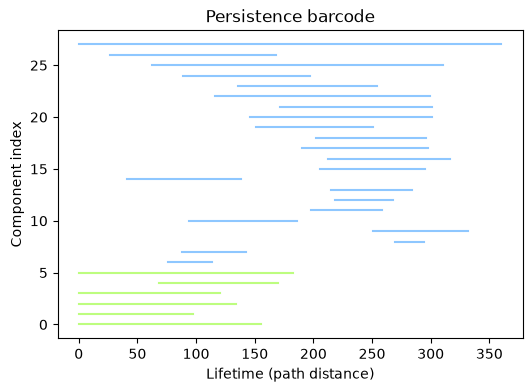

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
for i in range(len(ph_basal)):
    xs = [ph_basal[i][0], ph_basal[i][1]]
    ys = [i, i]
    ax.plot(xs, ys, color='lawngreen', alpha=0.5)
for j in range(len(ph_apical)):
    xs = [ph_apical[j][0], ph_apical[j][1]]
    ys = [j + len(ph_basal), j + len(ph_basal)]
    ax.plot(xs, ys, color='dodgerblue', alpha=0.5)
ax.set_xlabel('Lifetime (path distance)')
ax.set_ylabel('Component index')
ax.set_title('Persistence barcode')

## Summary

In [ ]:
apical_trees = cell.apical_dendrite
n_tips = sum([len(tree.get_terminations()) for tree in apical_trees])
print(f'The number of trees: {len(apical_trees)}')
print(f'The number of tips: {n_tips}')
print(f'The number of of persistence pairs: {len(ph_apical)}')
print(f'The largest birth value: {max([pair[0] for pair in ph_apical])}')

The number of trees: 1
The number of tips: 22
The number of of persistence pairs: 22
The largest birth value: 360.32571156322956


In [7]:
basal_trees = cell.basal_dendrite
n_tips = sum([len(tree.get_terminations()) for tree in basal_trees])
print(f'The number of trees: {len(basal_trees)}')
print(f'The number of tips: {n_tips}')
print(f'The number of of persistence pairs: {len(ph_basal)}')
print(f'The largest birth value: {max([pair[0] for pair in ph_basal])}')

The number of trees: 5
The number of tips: 6
The number of of persistence pairs: 6
The largest birth value: 182.74114610254765


## Persistence diagram

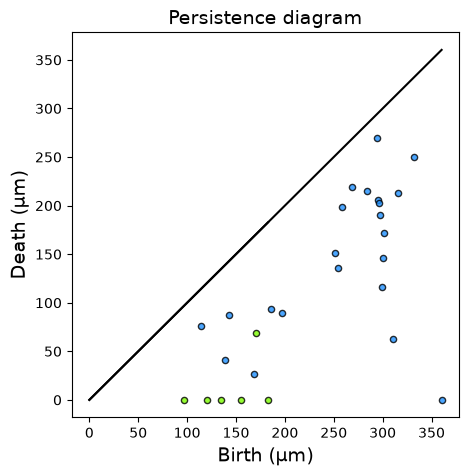

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
plt.sca(ax)
plot.diagram(ph_apical, new_fig=False, color='dodgerblue', s=20, alpha=0.8)
plot.diagram(ph_basal, new_fig=False, color='lawngreen', s=20, alpha=0.8,
             title='Persistence diagram', 
             xlabel='Birth (µm)', ylabel='Death (µm)');

## Persistence image

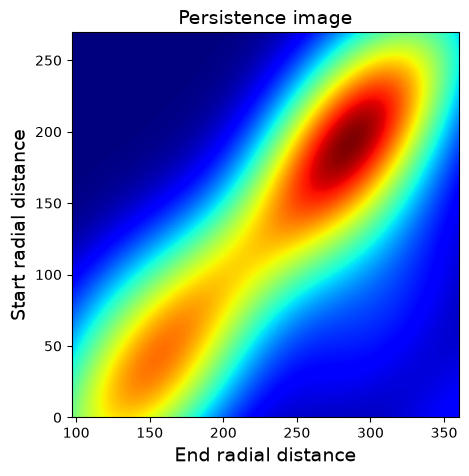

In [ ]:
ph_all = ph_apical + ph_basal
fig, ax = plt.subplots(figsize=(5, 5))
plt.sca(ax)
plot.persistence_image(ph_all, new_fig=False);